# SGC Spotify · Prototipo final
**Clasificación, recomendación, chatbot y grafo de conocimiento integrados**

Este cuaderno recorre los cuatro componentes del sistema con el mismo código que usa la aplicación web (`app.py`).
Las salidas que ves ya vienen ejecutadas; si quieres volver a correrlo en Colab, ejecuta la primera celda para descargar el repositorio.

> Los documentos son **simulados**: se redactaron para el proyecto con base en información pública sobre cómo trabaja Spotify.

In [1]:
# Solo en Google Colab: descarga el repositorio (cambia TU-USUARIO por tu usuario de GitHub)
# !git clone https://github.com/TU-USUARIO/sgc-spotify.git
# %cd sgc-spotify
# !pip install -q -r requirements.txt

## 1. Cargar el sistema integrado
Al crear `SistemaConocimiento` pasan cuatro cosas en orden: se entrena el clasificador con los 40 documentos etiquetados, se clasifican los 6 nuevos, se arma el índice semántico con los 46 y se construye el grafo con la ontología.

In [2]:
from sgc.sistema import SistemaConocimiento
s = SistemaConocimiento()
print("Documentos en el repositorio:", len(s.documentos))
print("Nodos del grafo:", s.grafo.G.number_of_nodes(), "| relaciones:", s.grafo.G.number_of_edges())

Documentos en el repositorio: 46
Nodos del grafo: 108 | relaciones: 254


## 2. Clasificación automática (mejorada)
En el avance se usó TF-IDF de palabras con Naive Bayes. Ahora se comparan cinco modelos con validación cruzada. Los fragmentos de caracteres ayudan a reconocer palabras de la misma familia (*desplegar / despliegue*).

In [3]:
from sgc.datos import cargar_documentos
from sgc.clasificador import comparar_modelos, evaluar_por_categoria
df = cargar_documentos()
ent = df[df["etiquetado"]]
X, y = ent["texto"].tolist(), ent["categoria"].tolist()
for f in comparar_modelos(X, y):
    print(f"{f['modelo']:42s} 5 partes: {f['exactitud_cv5']:.1%}   5 partes x 10: {f['exactitud_cv5x10']:.1%}")

Naive Bayes · palabras (avance)            5 partes: 90.0%   5 partes x 10: 87.5%
Regresión Logística · palabras (avance)    5 partes: 87.5%   5 partes x 10: 85.2%
Naive Bayes · caracteres                   5 partes: 92.5%   5 partes x 10: 90.8%
SVM lineal · caracteres                    5 partes: 92.5%   5 partes x 10: 93.0%
Regresión Logística · caracteres           5 partes: 92.5%   5 partes x 10: 92.0%


In [4]:
ev = evaluar_por_categoria(X, y)
print(f"{'Categoría':30s} {'Precisión':>9s} {'Recall':>7s}")
for c in ev["por_categoria"]:
    print(f"{c['categoria']:30s} {c['precision']:9.1%} {c['recall']:7.1%}")
print(f"{'Promedio macro':30s} {ev['macro']['precision']:9.1%} {ev['macro']['recall']:7.1%}")

Categoría                      Precisión  Recall
Documentación técnica              85.7%   75.0%
Reporte de incidente               88.9%  100.0%
Resultado de experimento A/B      100.0%  100.0%
Política interna                   87.5%   87.5%
Investigación de usuarios         100.0%  100.0%
Promedio macro                     92.4%   92.5%


In [5]:
for d in s.documentos:
    if d["nuevo"]:
        print(f"{d['id']:8s} {d['categoria']:30s} {d['confianza']:.0%}  {d['titulo']}")

NUEVO01  Documentación técnica          85%  Guía de instalación del servicio de búsqueda
NUEVO02  Reporte de incidente           87%  Postmortem: interrupción de descargas sin conexión
NUEVO03  Resultado de experimento A/B   96%  Resultado de prueba A/B: botón de mezcla aleatoria
NUEVO04  Política interna               83%  Política de uso de datos para entrenar modelos
NUEVO05  Investigación de usuarios      85%  Hallazgos de entrevistas con usuarios de audiolibros
NUEVO06  Documentación técnica          89%  Manual de respuesta ante alertas del servicio de cuentas


## 3. Recomendaciones
### 3.1 Por similitud semántica entre documentos
Para cada sugerencia se muestra la similitud coseno, los términos en común y los conceptos que comparten en el grafo.

In [6]:
def ver(recs):
    for r in recs:
        print(f"  [{r['id']}] {r['titulo']}")
        print(f"      similitud {r['similitud']:.3f} | términos: {', '.join(r['terminos'])} | conceptos: {', '.join(r['conceptos']) or '—'}")

for doc in ["RI01", "EX04", "PO01"]:
    print(f"Relacionados con [{doc}] {s.doc(doc)['titulo']}:")
    ver(s.recomendador.relacionados(doc, k=3))
    print()

Relacionados con [RI01] Postmortem: caída del servicio de pagos:
  [RI08] Postmortem: cobro duplicado a suscriptores
      similitud 0.152 | términos: pagos, servicio pagos, proveedor, incidente prioridad | conceptos: Premium y suscripciones, Servicio de pagos
  [NUEVO02] Postmortem: interrupción de descargas sin conexión
      similitud 0.151 | términos: conexion, agrego alerta, agrego, incidente prioridad | conceptos: Monitoreo y alertas
  [DT01] Guía de despliegue del servicio de pagos
      similitud 0.103 | términos: pagos, servicio pagos, servicio, minutos | conceptos: Monitoreo y alertas, Servicio de pagos

Relacionados con [EX04] Experimento con recomendaciones de podcasts:
  [IU02] Investigación sobre hábitos de escucha de podcasts
      similitud 0.172 | términos: podcasts, escucha, recomendaciones | conceptos: Podcasts, Sistema de recomendaciones
  [EX02] Experimento: nuevo diseño de la pantalla de inicio
      similitud 0.148 | términos: experimento, musica, escucha, probo 

### 3.2 Por historial de búsqueda
Las consultas recientes pesan más. Cada sugerencia dice qué consulta la motivó.

In [7]:
historial = ["caída del servicio de pagos", "certificado vencido"]
for r in s.recomendador.por_historial(historial, k=3):
    print(f"[{r['id']}] {r['titulo']}  ->  {r['motivo']} (similitud {r['similitud']:.3f})")

[RI01] Postmortem: caída del servicio de pagos  ->  porque buscaste: "certificado vencido" (similitud 0.259)
[DT01] Guía de despliegue del servicio de pagos  ->  porque buscaste: "caída del servicio de pagos" (similitud 0.052)
[RI08] Postmortem: cobro duplicado a suscriptores  ->  porque buscaste: "caída del servicio de pagos" (similitud 0.031)


## 4. Chatbot
Detecta la intención con reglas, recupera los documentos más parecidos, elige las oraciones que mejor responden y añade el contexto del grafo.

In [8]:
for q in ["¿Qué pasó con los cobros duplicados a los suscriptores?",
          "¿Qué hago si se activa una alerta en un servicio?",
          "¿Puedo trabajar desde otro país?",
          "qué documentos hay sobre Servicio de pagos"]:
    r = s.chatbot.responder(q)
    print("PREGUNTA:", q)
    print(r["respuesta"].replace("**", ""))
    if r["intencion"] == "contenido":
        print("FUENTES:", ", ".join(f"{f['id']} ({f['similitud']:.3f})" for f in r["fuentes"]))
    print("-" * 90)

PREGUNTA: ¿Qué pasó con los cobros duplicados a los suscriptores?
Según [RI08] Postmortem: cobro duplicado a suscriptores (Reporte de incidente, similitud 0.34):

> Un reintento automático en el servicio de pagos generó cobros duplicados a un grupo de suscriptores Premium. Se reembolsó a los usuarios afectados, se corrigió la lógica de reintentos con un identificador único por transacción y se agregaron pruebas que simulan fallas del proveedor.

*Contexto del grafo:* este tipo de documento lo genera Ingeniería de plataforma y lo consultan ingeniería y liderazgo técnico. Conceptos relacionados: Servicio de pagos, Premium y suscripciones, Pruebas automatizadas.
FUENTES: RI08 (0.341)
------------------------------------------------------------------------------------------
PREGUNTA: ¿Qué hago si se activa una alerta en un servicio?
Según [NUEVO06] Manual de respuesta ante alertas del servicio de cuentas (Documentación técnica, similitud 0.31):

> Cuando se activa una alerta del servicio d

## 5. Grafo de conocimiento
Amplía el grafo conceptual de la fase I con documentos, conceptos concretos y dos clases nuevas (*Causa raíz* y *Práctica de ingeniería*).

In [9]:
r = s.grafo.resumen()
print("Nodos por tipo:", r["por_tipo"])
print("\nConexiones de 'Credencial o certificado vencido':")
for fila in s.grafo.conexiones("concepto:Credencial o certificado vencido"):
    print("  ", *fila)

Nodos por tipo: {'clase': 12, 'categoria': 5, 'area': 4, 'concepto': 41, 'documento': 46}

Conexiones de 'Credencial o certificado vencido':
   → es un Causa raíz clase
   ← menciona RI01 documento
   ← menciona RI05 documento


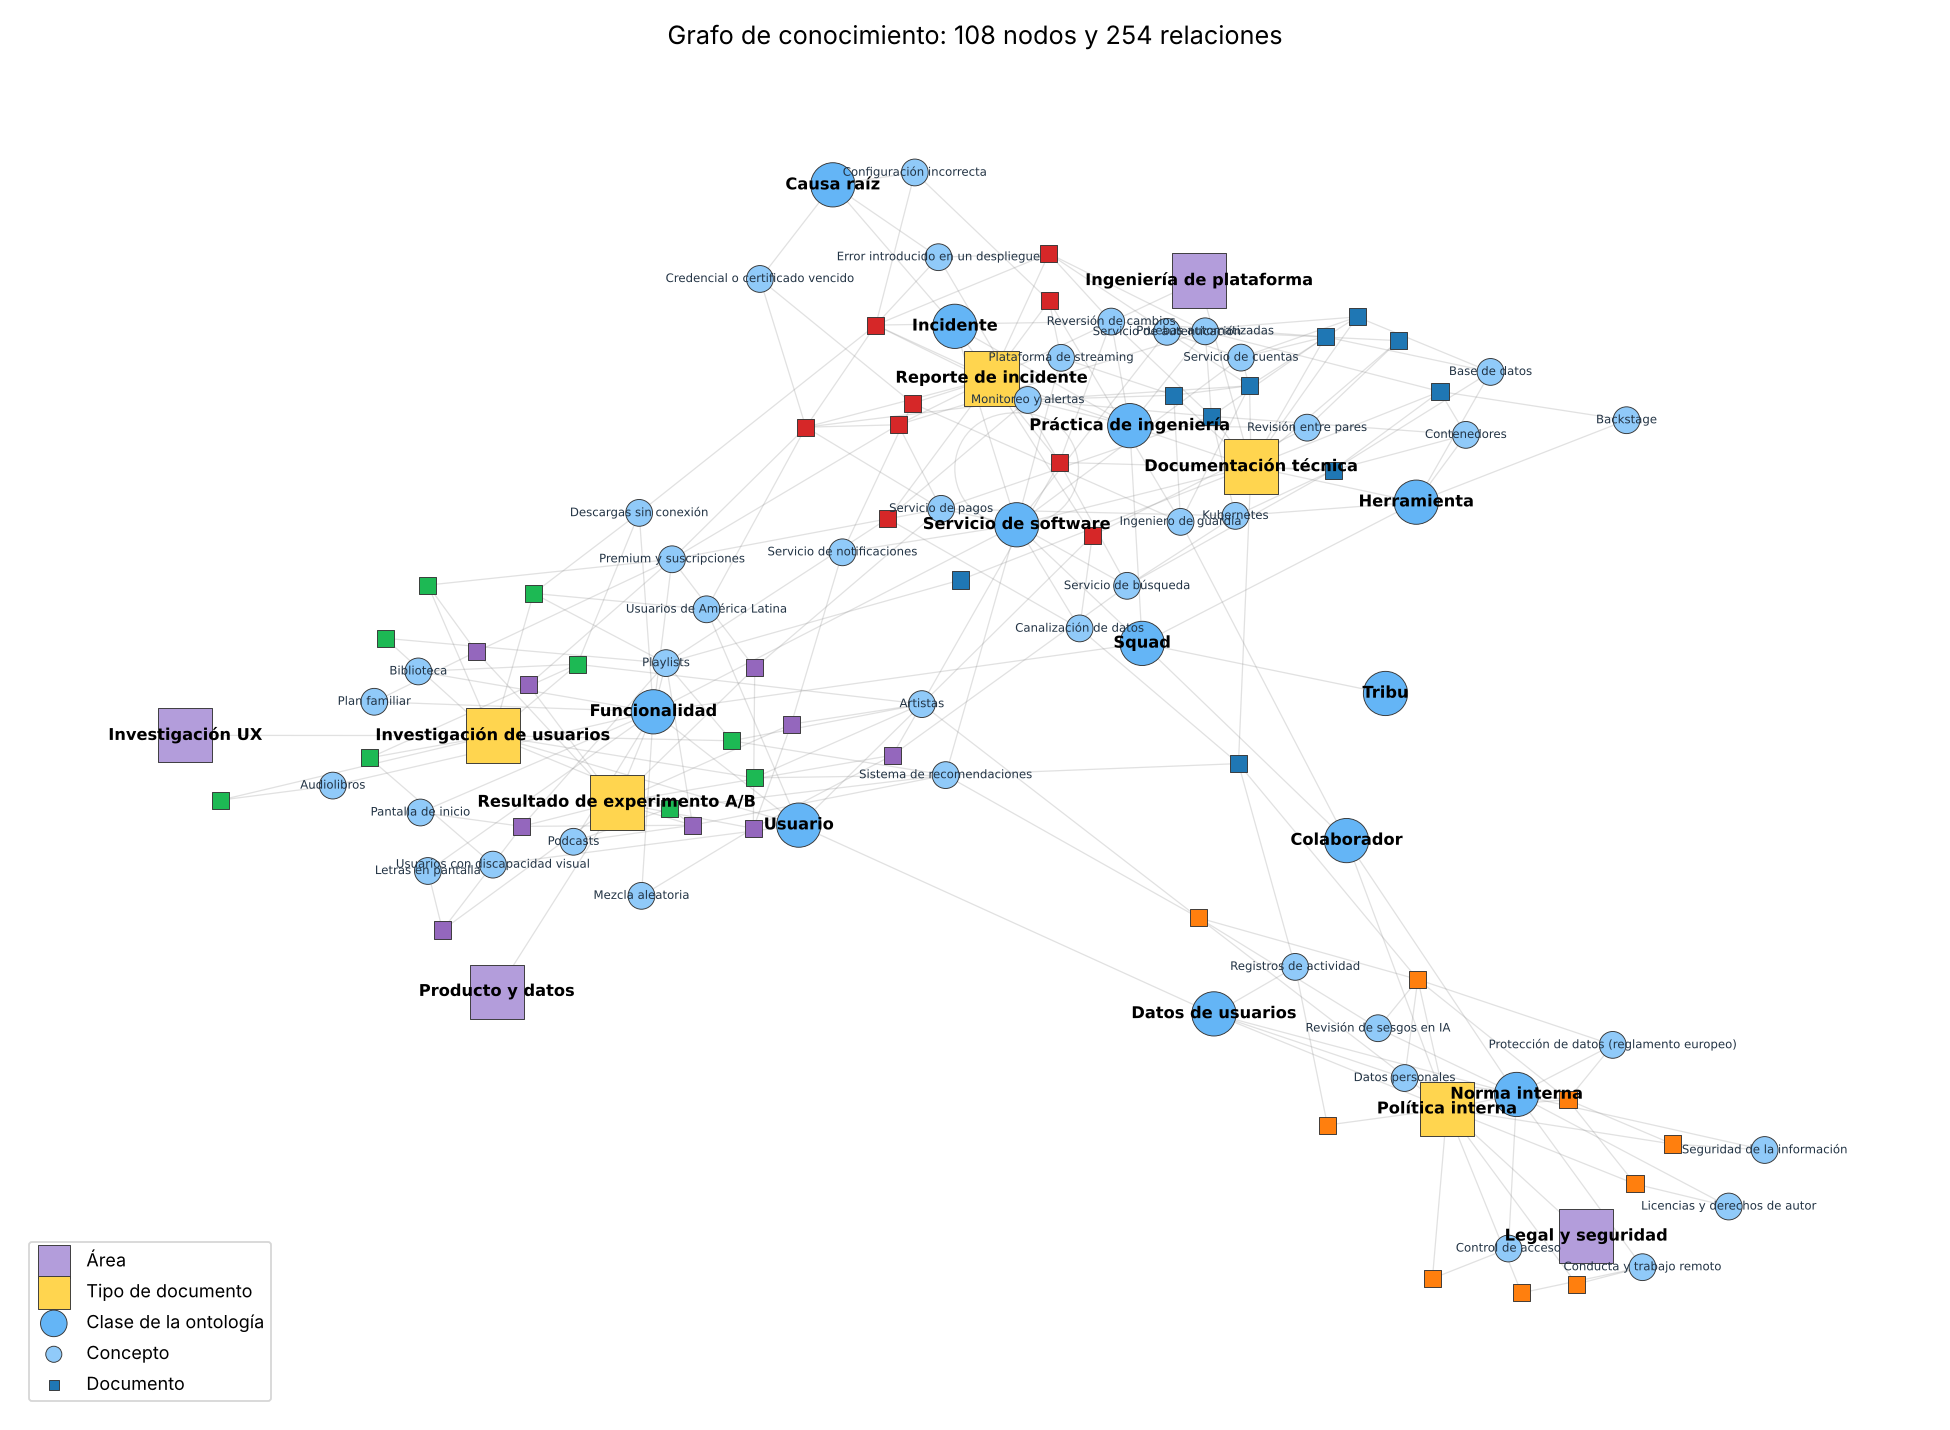

In [10]:
from IPython.display import Image
Image("evidencias/grafo_conocimiento.png")

## 6. Integración: un documento nuevo recorre todo el sistema

In [11]:
d, r = s.agregar_documento(
    "Postmortem: falla en la reproducción de podcasts",
    "Durante una hora los usuarios no pudieron reproducir episodios de podcasts. La causa raíz fue un certificado "
    "vencido en el servidor de entrega de contenido. El squad renovó el certificado y agregó una alerta preventiva.")
print(f"1) Clasificador: {d['id']} -> {r['categoria']} ({r['confianza']:.0%})")
print("2) Grafo: conceptos detectados ->", ", ".join(s.grafo.conceptos_de(d["id"])))
print("3) Recomendador: relacionados ->", [x["id"] for x in s.recomendador.relacionados(d["id"])])
print("4) Chatbot:")
print(s.chatbot.responder("¿Qué incidentes fueron causados por un certificado vencido?")["respuesta"].replace("**", ""))

1) Clasificador: USR01 -> Reporte de incidente (91%)
2) Grafo: conceptos detectados -> Plataforma de streaming, Podcasts, Credencial o certificado vencido, Monitoreo y alertas
3) Recomendador: relacionados -> ['RI01', 'NUEVO02', 'RI03']
4) Chatbot:
Según [USR01] Postmortem: falla en la reproducción de podcasts (Reporte de incidente, similitud 0.30):

> La causa raíz fue un certificado vencido en el servidor de entrega de contenido. El squad renovó el certificado y agregó una alerta preventiva.

También te puede servir [RI01] Postmortem: caída del servicio de pagos (similitud 0.22): La causa raíz fue un certificado vencido en la conexión con el proveedor de pagos.

*Conectados en el grafo:* [RI05] Reporte de incidente: falla en notificaciones push (comparte «Credencial o certificado vencido»)

*Contexto del grafo:* este tipo de documento lo genera Ingeniería de plataforma y lo consultan ingeniería y liderazgo técnico. Conceptos relacionados: Plataforma de streaming, Podcasts, Credencial

## 7. Evaluación completa
El script `scripts/evaluar_sistema.py` calcula todas las métricas y guarda la evidencia en `evidencias/`.

In [12]:
import json
m = json.load(open("evidencias/metricas.json", encoding="utf-8"))
b, rc = m["busqueda"]["resumen"], m["recomendaciones"]["resumen"]
print(f"Búsqueda (15 preguntas, k=3): precisión@3 {b['precision@k']:.1%} | recall@3 {b['recall@k']:.1%} | 1.er resultado correcto {b['acierto@1']:.0%}")
print(f"Recomendaciones (10 casos): precisión@3 {rc['precision@k']:.1%} | recall@3 {rc['recall@k']:.1%} | con al menos un acierto {rc['al_menos_uno']:.0%}")
print(f"Recomendaciones por historial (3 casos): precisión@3 {rc['historial_precision@k']:.0%}")

Búsqueda (15 preguntas, k=3): precisión@3 44.4% | recall@3 97.8% | 1.er resultado correcto 100%
Recomendaciones (10 casos): precisión@3 46.7% | recall@3 51.7% | con al menos un acierto 100%
Recomendaciones por historial (3 casos): precisión@3 100%
